# National bike safety data coverage check

This notebook checks whether the workbook contains observations for eight jurisdictions in every year from 2018 through 2024. The year-by-jurisdiction table displays the number of records in each cell; a complete panel should contain exactly one record in every cell.

In [1]:
from pathlib import Path
import pandas as pd

DATA_FILE = Path.cwd() / "National Bike Safety Data.xlsx"
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Safety workbook not found: {DATA_FILE}")

safety = pd.read_excel(DATA_FILE, sheet_name="National_Safety_Data")
safety["Year"] = pd.to_numeric(safety["Year"], errors="raise")
safety["State"] = safety["State"].astype("string").str.strip()
if safety[["Year", "State"]].isna().any().any():
    raise ValueError("Year or jurisdiction is missing from one or more records.")

expected_years = list(range(2018, 2025))
jurisdictions = sorted(safety["State"].unique().tolist())
coverage = pd.crosstab(safety["Year"], safety["State"]).reindex(
    index=expected_years, columns=jurisdictions, fill_value=0
)
pair_counts = safety.groupby(["Year", "State"]).size()
duplicate_pairs = pair_counts[pair_counts > 1]
missing_pairs = [
    (year, jurisdiction)
    for year in expected_years
    for jurisdiction in jurisdictions
    if coverage.loc[year, jurisdiction] == 0
]

display(coverage)
print(f"Jurisdictions ({len(jurisdictions)}): {', '.join(jurisdictions)}")
print(f"Years observed: {sorted(safety['Year'].unique().tolist())}")
print(f"Records: {len(safety)}; expected for a complete 8 x 7 panel: {8 * len(expected_years)}")
print(f"Missing year-jurisdiction pairs: {missing_pairs}")
print(f"Duplicate year-jurisdiction pairs: {duplicate_pairs.to_dict()}")

if len(jurisdictions) != 8:
    raise ValueError(f"Expected 8 jurisdictions; found {len(jurisdictions)}.")
if sorted(safety["Year"].unique().tolist()) != expected_years:
    raise ValueError("Observed years do not exactly cover 2018-2024.")
if missing_pairs or not duplicate_pairs.empty:
    raise ValueError("Coverage is incomplete or contains duplicate year-jurisdiction records.")
print("Coverage check: PASS — one record for each of 8 jurisdictions in every year from 2018 through 2024.")

State,CT,DC,MA,MD,NJ,NY,PA,VA
Year,,,,,,,,
2018,1,1,1,1,1,1,1,1
2019,1,1,1,1,1,1,1,1
2020,1,1,1,1,1,1,1,1
2021,1,1,1,1,1,1,1,1
2022,1,1,1,1,1,1,1,1
2023,1,1,1,1,1,1,1,1
2024,1,1,1,1,1,1,1,1


Jurisdictions (8): CT, DC, MA, MD, NJ, NY, PA, VA
Years observed: [2018, 2019, 2020, 2021, 2022, 2023, 2024]
Records: 56; expected for a complete 8 x 7 panel: 56
Missing year-jurisdiction pairs: []
Duplicate year-jurisdiction pairs: {}
Coverage check: PASS — one record for each of 8 jurisdictions in every year from 2018 through 2024.


## Missing years, duplicates, negative values, and totals

This checks the full 2018–2024 period, duplicate jurisdiction-year keys, negative numeric measures, and whether reported cyclist injury or fatality counts exceed total crashes. The latter is only a basic anomaly screen, not a strict accounting identity: the workbook does not define whether multiple cyclists can be injured in one crash.

The workbook contains no separate national annual total to reconcile against. The yearly totals below are sums of the eight jurisdiction rows only, not independently verified national totals.

In [2]:
numeric_fields = [
    "Total_Crashes", "Cyclist_Injuries", "Cyclist_Fatalities",
    "Urban_Percent", "Protected_Lane_Miles",
]
numeric_data = safety[numeric_fields].apply(pd.to_numeric, errors="raise")
negative_value_count = int(numeric_data.lt(0).sum().sum())
missing_years = sorted(set(expected_years) - set(safety["Year"].unique()))
extra_years = sorted(set(safety["Year"].unique()) - set(expected_years))
duplicate_keys = (
    safety.groupby(["Year", "State"]).size()
    .loc[lambda counts: counts > 1]
)
urban_percent_out_of_range = int((~numeric_data["Urban_Percent"].between(0, 100)).sum())
injuries_exceed_crashes = int((safety["Cyclist_Injuries"] > safety["Total_Crashes"]).sum())
fatalities_exceed_crashes = int((safety["Cyclist_Fatalities"] > safety["Total_Crashes"]).sum())

quality_checks = pd.DataFrame([
    {"Check": "Missing expected years", "Findings": str(missing_years)},
    {"Check": "Unexpected years", "Findings": str(extra_years)},
    {"Check": "Duplicate (Year, State) keys", "Findings": str(duplicate_keys.to_dict())},
    {"Check": "Negative numeric values", "Findings": str(negative_value_count)},
    {"Check": "Urban_Percent outside 0-100", "Findings": str(urban_percent_out_of_range)},
    {"Check": "Rows with injuries > total crashes", "Findings": str(injuries_exceed_crashes)},
    {"Check": "Rows with fatalities > total crashes", "Findings": str(fatalities_exceed_crashes)},
])
display(quality_checks)

annual_totals = safety.groupby("Year").agg(
    Jurisdiction_records=("State", "size"),
    Unique_jurisdictions=("State", "nunique"),
    Total_Crashes_sum=("Total_Crashes", "sum"),
    Cyclist_Injuries_sum=("Cyclist_Injuries", "sum"),
    Cyclist_Fatalities_sum=("Cyclist_Fatalities", "sum"),
).reindex(expected_years)
annual_totals.loc["All years (sum)"] = {
    "Jurisdiction_records": len(safety),
    "Unique_jurisdictions": safety["State"].nunique(),
    "Total_Crashes_sum": safety["Total_Crashes"].sum(),
    "Cyclist_Injuries_sum": safety["Cyclist_Injuries"].sum(),
    "Cyclist_Fatalities_sum": safety["Cyclist_Fatalities"].sum(),
}
display(annual_totals.style.format({
    "Total_Crashes_sum": "{:,.0f}",
    "Cyclist_Injuries_sum": "{:,.0f}",
    "Cyclist_Fatalities_sum": "{:,.0f}",
}))

jurisdiction_totals = safety.groupby("State").agg(
    Years_covered=("Year", "nunique"),
    Records=("Year", "size"),
    Total_Crashes_sum=("Total_Crashes", "sum"),
    Cyclist_Injuries_sum=("Cyclist_Injuries", "sum"),
    Cyclist_Fatalities_sum=("Cyclist_Fatalities", "sum"),
).sort_index()
jurisdiction_totals.loc["All jurisdictions (sum)"] = {
    "Years_covered": safety["Year"].nunique(),
    "Records": len(safety),
    "Total_Crashes_sum": safety["Total_Crashes"].sum(),
    "Cyclist_Injuries_sum": safety["Cyclist_Injuries"].sum(),
    "Cyclist_Fatalities_sum": safety["Cyclist_Fatalities"].sum(),
}
display(jurisdiction_totals.style.format({
    "Total_Crashes_sum": "{:,.0f}",
    "Cyclist_Injuries_sum": "{:,.0f}",
    "Cyclist_Fatalities_sum": "{:,.0f}",
}))
print("Totals are sums of the 56 jurisdiction-year records; the workbook provides no independent national totals for reconciliation.")

if missing_years or extra_years or not duplicate_keys.empty:
    raise ValueError("Year coverage or jurisdiction-year uniqueness check failed.")
if negative_value_count or urban_percent_out_of_range:
    raise ValueError("Negative numeric values or out-of-range urban percentages were found.")

,Check,Findings
0,Missing expected years,[]
1,Unexpected years,[]
2,"Duplicate (Year, State) keys",{}
3,Negative numeric values,0
4,Urban_Percent outside 0-100,0
5,Rows with injuries > total crashes,0
6,Rows with fatalities > total crashes,0


,Jurisdiction_records,Unique_jurisdictions,Total_Crashes_sum,Cyclist_Injuries_sum,Cyclist_Fatalities_sum
Year,,,,,
2018,8,8,"24,839","17,945",459
2019,8,8,"21,019","15,962",411
2020,8,8,"27,817","19,714",511
2021,8,8,"23,536","16,621",465
2022,8,8,"19,202","14,308",434
2023,8,8,"19,014","13,995",344
2024,8,8,"21,956","15,889",383
All years (sum),56,8,"157,383","114,434","3,007"


,Years_covered,Records,Total_Crashes_sum,Cyclist_Injuries_sum,Cyclist_Fatalities_sum
State,,,,,
CT,7,7,"21,012","14,870",425
DC,7,7,"21,496","15,836",405
MA,7,7,"20,785","15,522",357
MD,7,7,"16,723","12,023",311
NJ,7,7,"16,962","12,134",358
NY,7,7,"18,252","13,444",271
PA,7,7,"23,926","17,742",562
VA,7,7,"18,227","12,863",318
All jurisdictions (sum),7,56,"157,383","114,434","3,007"


Totals are sums of the 56 jurisdiction-year records; the workbook provides no independent national totals for reconciliation.


## Annual crashes, injuries, and fatalities trend

Annual totals sum the eight jurisdiction records for each year. These are workbook totals rather than independently verified national counts, and raw counts are not adjusted for population or cycling exposure.

,Total_Crashes,Cyclist_Injuries,Cyclist_Fatalities
Year,,,
2018,"24,839","17,945",459
2019,"21,019","15,962",411
2020,"27,817","19,714",511
2021,"23,536","16,621",465
2022,"19,202","14,308",434
2023,"19,014","13,995",344
2024,"21,956","15,889",383


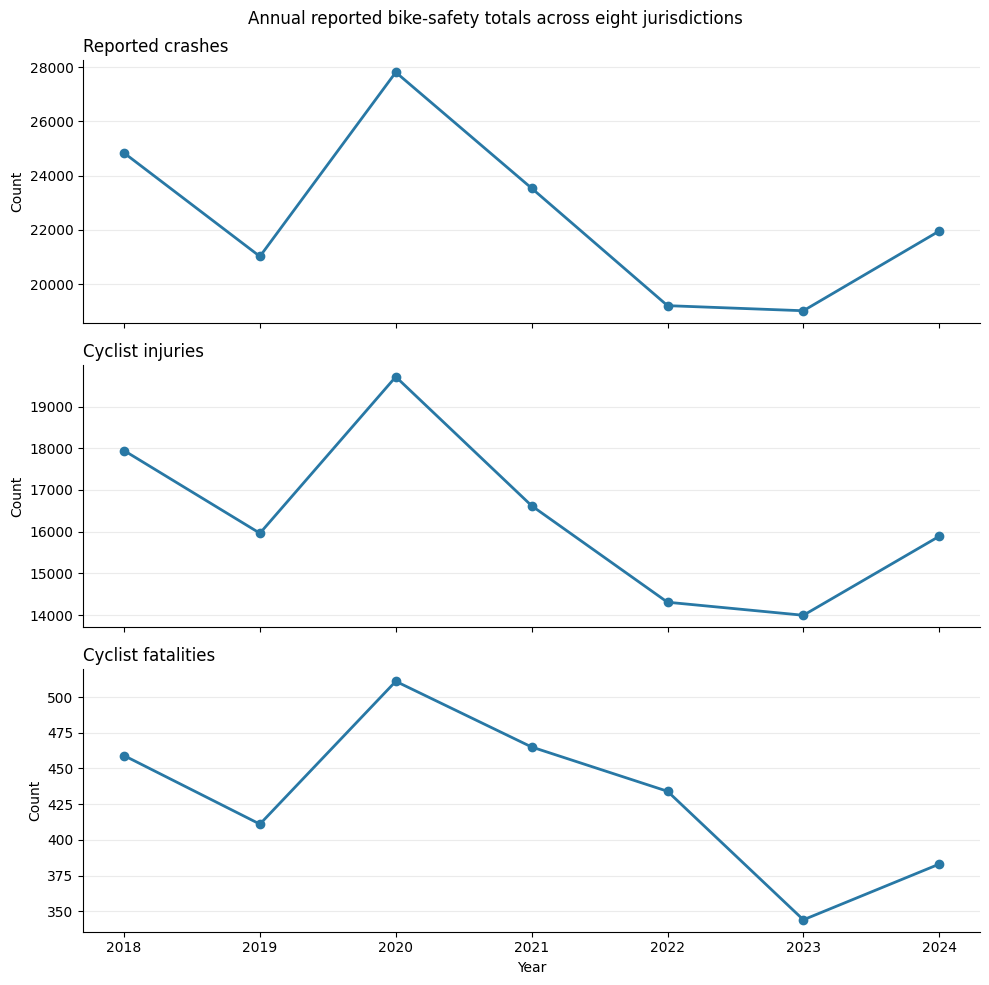

In [3]:
annual_trend = safety.groupby("Year").agg(
    Total_Crashes=("Total_Crashes", "sum"),
    Cyclist_Injuries=("Cyclist_Injuries", "sum"),
    Cyclist_Fatalities=("Cyclist_Fatalities", "sum"),
).reindex(expected_years)
display(annual_trend.style.format("{:,.0f}"))
import matplotlib.pyplot as plt

trend_metrics = [
    ("Total_Crashes", "Reported crashes"),
    ("Cyclist_Injuries", "Cyclist injuries"),
    ("Cyclist_Fatalities", "Cyclist fatalities"),
]
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, (metric, label) in zip(axes, trend_metrics):
    ax.plot(annual_trend.index, annual_trend[metric], marker="o", linewidth=2, color="#2878A5")
    ax.set_ylabel("Count")
    ax.set_title(label, loc="left")
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(expected_years)
axes[-1].set_xlabel("Year")
fig.suptitle("Annual reported bike-safety totals across eight jurisdictions")
fig.tight_layout()
plt.show()

## Cyclist injury and fatality rates by jurisdiction and year

Rates are calculated as `Cyclist_Injuries / Total_Crashes * 100` and `Cyclist_Fatalities / Total_Crashes * 100`, and are reported per 100 recorded total crashes. They are descriptive ratios, not cyclist risk per trip, person, or mile. The workbook does not define the crash denominator in greater detail.

,State,Year,Total_Crashes,Injuries per 100 crashes,Fatalities per 100 crashes
4,CT,2018,"2,935",83.61,2.25
12,CT,2019,"4,733",66.60,1.50
20,CT,2020,"2,944",74.80,2.04
28,CT,2021,"1,583",66.90,1.77
36,CT,2022,"3,151",64.33,1.81
44,CT,2023,"1,165",72.36,2.83
52,CT,2024,"4,501",69.61,2.44
7,DC,2018,"3,242",60.73,1.70
15,DC,2019,"2,157",69.73,2.74
23,DC,2020,"3,652",75.71,1.53


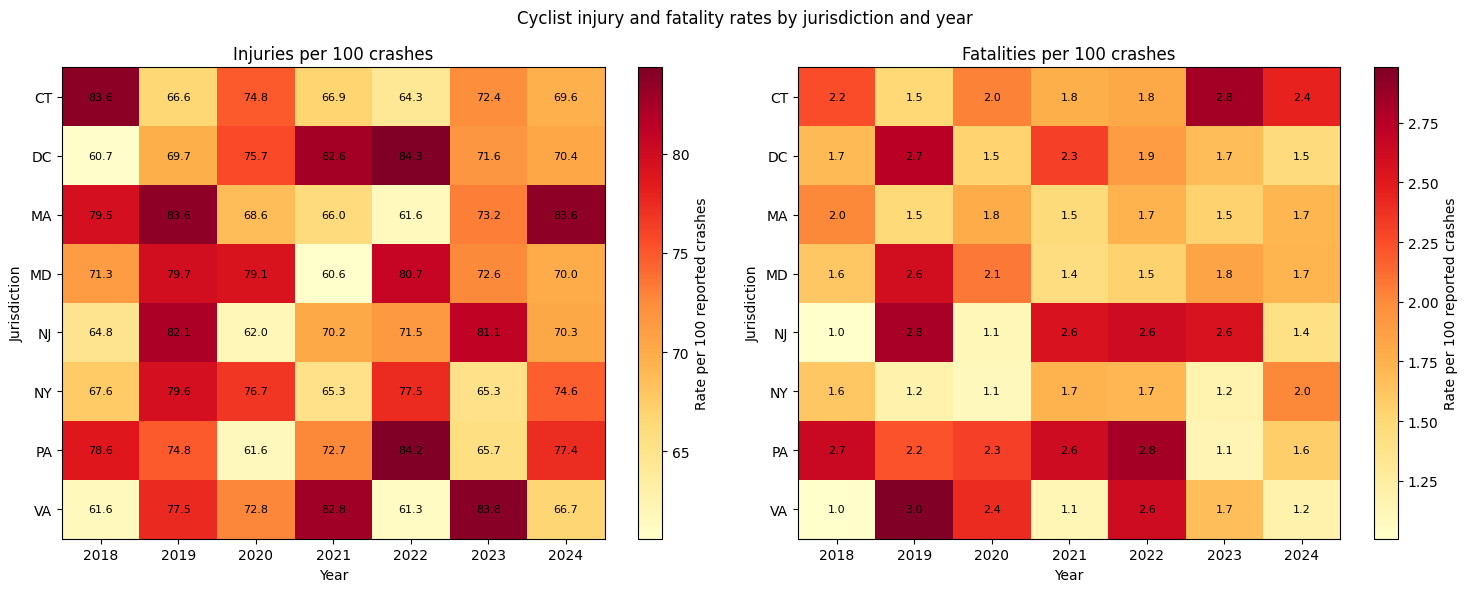

In [4]:
if safety["Total_Crashes"].le(0).any():
    raise ValueError("Rates cannot be calculated because Total_Crashes contains zero or negative denominators.")

rate_data = safety.copy()
rate_data["Injuries per 100 crashes"] = (
    rate_data["Cyclist_Injuries"] / rate_data["Total_Crashes"] * 100
)
rate_data["Fatalities per 100 crashes"] = (
    rate_data["Cyclist_Fatalities"] / rate_data["Total_Crashes"] * 100
)
rate_table = rate_data[[
    "State", "Year", "Total_Crashes",
    "Injuries per 100 crashes", "Fatalities per 100 crashes",
]].sort_values(["State", "Year"])
display(rate_table.style.format({
    "Total_Crashes": "{:,.0f}",
    "Injuries per 100 crashes": "{:.2f}",
    "Fatalities per 100 crashes": "{:.2f}",
}))

import matplotlib.pyplot as plt
rate_metrics = ["Injuries per 100 crashes", "Fatalities per 100 crashes"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric in zip(axes, rate_metrics):
    rate_grid = rate_data.pivot(index="State", columns="Year", values=metric).reindex(
        index=sorted(rate_data["State"].unique()), columns=expected_years
    )
    image = ax.imshow(rate_grid, aspect="auto", cmap="YlOrRd")
    ax.set_xticks(range(len(expected_years)), labels=expected_years)
    ax.set_yticks(range(len(rate_grid.index)), labels=rate_grid.index)
    ax.set_xlabel("Year")
    ax.set_ylabel("Jurisdiction")
    ax.set_title(metric)
    for row in range(rate_grid.shape[0]):
        for column in range(rate_grid.shape[1]):
            ax.text(column, row, f"{rate_grid.iloc[row, column]:.1f}",
                    ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, label="Rate per 100 reported crashes")
fig.suptitle("Cyclist injury and fatality rates by jurisdiction and year")
fig.tight_layout()
plt.show()

## Average protected-lane mileage by jurisdiction

The average is the arithmetic mean of the seven annual `Protected_Lane_Miles` observations for each jurisdiction from 2018 through 2024.

,Years_reported,Average_protected_lane_miles,Minimum_protected_lane_miles,Maximum_protected_lane_miles
State,,,,
VA,7,325.3,110,463
NY,7,305.7,137,478
CT,7,263.1,64,372
MA,7,262.7,110,491
DC,7,257.7,100,493
NJ,7,252.4,58,478
PA,7,243.7,85,421
MD,7,193.9,58,326


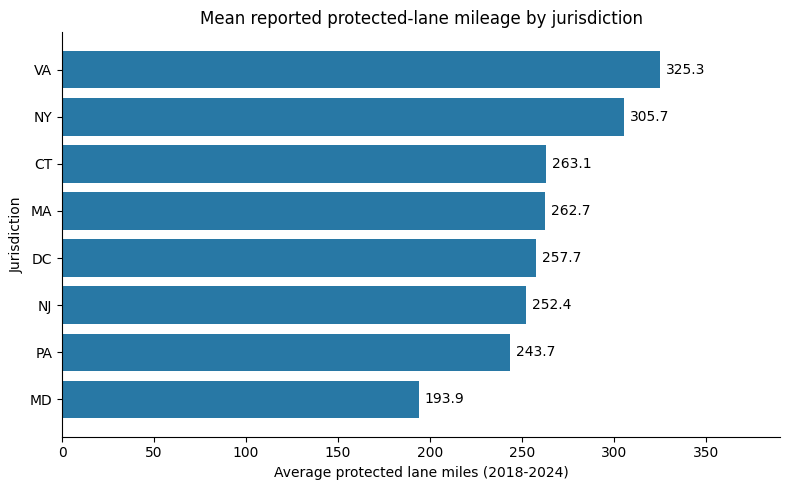

In [5]:
protected_lane_summary = safety.groupby("State").agg(
    Years_reported=("Year", "nunique"),
    Average_protected_lane_miles=("Protected_Lane_Miles", "mean"),
    Minimum_protected_lane_miles=("Protected_Lane_Miles", "min"),
    Maximum_protected_lane_miles=("Protected_Lane_Miles", "max"),
).sort_values("Average_protected_lane_miles", ascending=False)
display(protected_lane_summary.style.format({
    "Average_protected_lane_miles": "{:.1f}",
    "Minimum_protected_lane_miles": "{:,.0f}",
    "Maximum_protected_lane_miles": "{:,.0f}",
}))

fig, ax = plt.subplots(figsize=(8, 5))
plot_values = protected_lane_summary["Average_protected_lane_miles"].sort_values()
bars = ax.barh(plot_values.index, plot_values.values, color="#2878A5")
ax.bar_label(bars, labels=[f"{value:.1f}" for value in plot_values.values], padding=4)
ax.set_xlim(0, plot_values.max() * 1.2)
ax.set_xlabel("Average protected lane miles (2018-2024)")
ax.set_ylabel("Jurisdiction")
ax.set_title("Mean reported protected-lane mileage by jurisdiction")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Most-protected versus least-protected jurisdiction groups

The most-protected group has average 2018–2024 protected-lane mileage above the jurisdiction median; the least-protected group is at or below it. Each jurisdiction contributes its seven-year mean annual rate per 100 reported crashes, and jurisdictions are weighted equally within each group. This is a descriptive comparison, not a causal test; the dataset does not control for population, cycling exposure, roadway size, or other factors.

Median mileage split: 260.2 miles


,Average_protected_lane_miles,Mean_injuries_per_100_crashes,Mean_fatalities_per_100_crashes,Mileage group
State,,,,
VA,325.3,72.36,1.86,Most protected
NY,305.7,72.36,1.50,Most protected
CT,263.1,71.17,2.09,Most protected
MA,262.7,73.72,1.68,Most protected
DC,257.7,73.59,1.90,Least protected
NJ,252.4,71.69,2.01,Least protected
PA,243.7,73.57,2.19,Least protected
MD,193.9,73.43,1.83,Least protected


,Jurisdictions,Mean_protected_lane_miles,Mean_state_injury_rate,Mean_state_fatality_rate
Mileage group,,,,
Most protected,4,289.2,72.40,1.78
Least protected,4,236.9,73.07,1.98


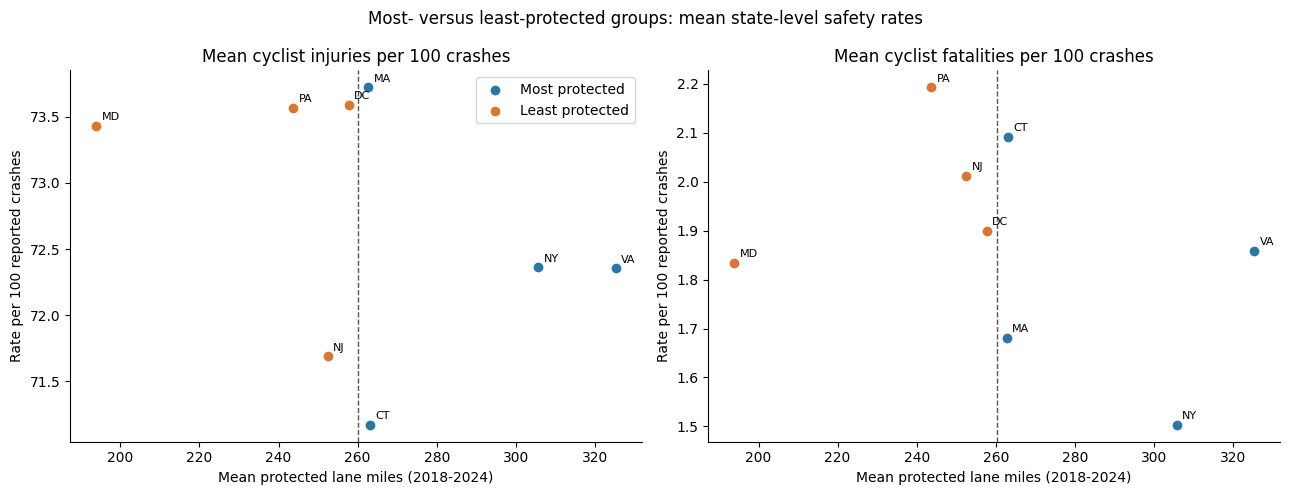

In [6]:
mean_rates_by_state = rate_data.groupby("State").agg(
    Mean_injuries_per_100_crashes=("Injuries per 100 crashes", "mean"),
    Mean_fatalities_per_100_crashes=("Fatalities per 100 crashes", "mean"),
)
mileage_comparison = protected_lane_summary[["Average_protected_lane_miles"]].join(mean_rates_by_state)
mileage_split = mileage_comparison["Average_protected_lane_miles"].median()
mileage_comparison["Mileage group"] = mileage_comparison["Average_protected_lane_miles"].gt(mileage_split).map(
    {True: "Most protected", False: "Least protected"}
)

group_comparison = mileage_comparison.groupby("Mileage group").agg(
    Jurisdictions=("Average_protected_lane_miles", "size"),
    Mean_protected_lane_miles=("Average_protected_lane_miles", "mean"),
    Mean_state_injury_rate=("Mean_injuries_per_100_crashes", "mean"),
    Mean_state_fatality_rate=("Mean_fatalities_per_100_crashes", "mean"),
).reindex(["Most protected", "Least protected"])

print(f"Median mileage split: {mileage_split:.1f} miles")
display(mileage_comparison.sort_values("Average_protected_lane_miles", ascending=False).style.format({
    "Average_protected_lane_miles": "{:.1f}",
    "Mean_injuries_per_100_crashes": "{:.2f}",
    "Mean_fatalities_per_100_crashes": "{:.2f}",
}))
display(group_comparison.style.format({
    "Mean_protected_lane_miles": "{:.1f}",
    "Mean_state_injury_rate": "{:.2f}",
    "Mean_state_fatality_rate": "{:.2f}",
}))

group_colors = {"Most protected": "#2878A5", "Least protected": "#D97732"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rate_axes = [
    ("Mean_injuries_per_100_crashes", "Mean cyclist injuries per 100 crashes"),
    ("Mean_fatalities_per_100_crashes", "Mean cyclist fatalities per 100 crashes"),
]
for ax, (rate_field, title) in zip(axes, rate_axes):
    for group, color in group_colors.items():
        subset = mileage_comparison.loc[mileage_comparison["Mileage group"].eq(group)]
        ax.scatter(subset["Average_protected_lane_miles"], subset[rate_field],
                   color=color, label=group)
        for state, row in subset.iterrows():
            ax.annotate(state, (row["Average_protected_lane_miles"], row[rate_field]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.axvline(mileage_split, color="#555555", linestyle="--", linewidth=1)
    ax.set_xlabel("Mean protected lane miles (2018-2024)")
    ax.set_ylabel("Rate per 100 reported crashes")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend()
fig.suptitle("Most- versus least-protected groups: mean state-level safety rates")
fig.tight_layout()
plt.show()

## Test: protected-lane mileage and fatality rate

The comparison table summarizes each jurisdiction's 2018–2024 crash, injury, and fatality totals, mean annual protected-lane mileage, and pooled rates per 100 reported crashes. The scatter plot compares mean protected-lane mileage with pooled cyclist fatalities per reported crash. Pearson tests linear association; Spearman tests rank association. The jurisdiction is the unit of analysis (n=8), avoiding treatment of repeated state-year rows as independent observations. This remains an ecological, unadjusted association test.

Interpretation: Pearson r = -0.48 indicates a negative directional association in this sample—jurisdictions with higher average protected-lane mileage tended to have lower pooled fatalities per 100 reported crashes. This is not a causal result, and it is not statistically significant (p = 0.228; n = 8). Spearman rho = -0.57 (p = 0.139) is also not statistically significant.

,Years_reported,Average_protected_lane_miles,Total_cyclist_injuries,Total_cyclist_fatalities,Total_reported_crashes,Injuries_per_100_crashes,Fatalities_per_crash,Fatalities_per_100_crashes
State,,,,,,,,
VA,7,325.3,"12,863",318,"18,227",70.57,0.01745,1.745
NY,7,305.7,"13,444",271,"18,252",73.66,0.01485,1.485
CT,7,263.1,"14,870",425,"21,012",70.77,0.02023,2.023
MA,7,262.7,"15,522",357,"20,785",74.68,0.01718,1.718
DC,7,257.7,"15,836",405,"21,496",73.67,0.01884,1.884
NJ,7,252.4,"12,134",358,"16,962",71.54,0.02111,2.111
PA,7,243.7,"17,742",562,"23,926",74.15,0.02349,2.349
MD,7,193.9,"12,023",311,"16,723",71.89,0.01860,1.860


,Test,Statistic,p-value
0,Pearson correlation,-0.480,0.228
1,Spearman rank correlation,-0.571,0.139


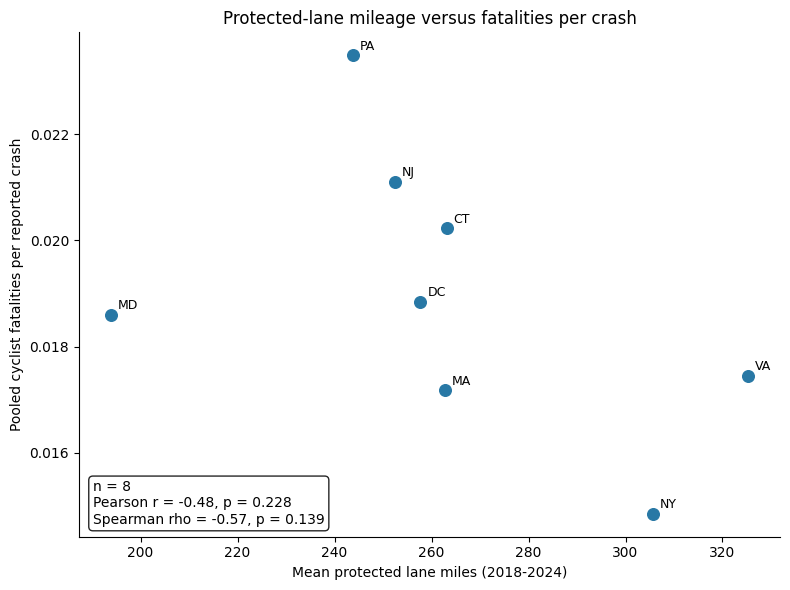

Neither test found a statistically significant association at the 0.05 level.


In [7]:
from scipy.stats import pearsonr, spearmanr

jurisdiction_comparison = safety.groupby("State").agg(
    Years_reported=("Year", "nunique"),
    Average_protected_lane_miles=("Protected_Lane_Miles", "mean"),
    Total_cyclist_injuries=("Cyclist_Injuries", "sum"),
    Total_cyclist_fatalities=("Cyclist_Fatalities", "sum"),
    Total_reported_crashes=("Total_Crashes", "sum"),
)
jurisdiction_comparison["Injuries_per_100_crashes"] = (
    jurisdiction_comparison["Total_cyclist_injuries"]
    / jurisdiction_comparison["Total_reported_crashes"] * 100
)
jurisdiction_comparison["Fatalities_per_crash"] = (
    jurisdiction_comparison["Total_cyclist_fatalities"]
    / jurisdiction_comparison["Total_reported_crashes"]
)
jurisdiction_comparison["Fatalities_per_100_crashes"] = (
    jurisdiction_comparison["Fatalities_per_crash"] * 100
)
if len(jurisdiction_comparison) < 3:
    raise ValueError("Too few jurisdictions to test the association.")

pearson_result = pearsonr(
    jurisdiction_comparison["Average_protected_lane_miles"],
    jurisdiction_comparison["Fatalities_per_crash"],
)
spearman_result = spearmanr(
    jurisdiction_comparison["Average_protected_lane_miles"],
    jurisdiction_comparison["Fatalities_per_crash"],
)
display(jurisdiction_comparison.sort_values("Average_protected_lane_miles", ascending=False).style.format({
    "Years_reported": "{:.0f}",
    "Average_protected_lane_miles": "{:.1f}",
    "Total_cyclist_injuries": "{:,.0f}",
    "Total_cyclist_fatalities": "{:,.0f}",
    "Total_reported_crashes": "{:,.0f}",
    "Injuries_per_100_crashes": "{:.2f}",
    "Fatalities_per_crash": "{:.5f}",
    "Fatalities_per_100_crashes": "{:.3f}",
}))

test_results = pd.DataFrame([
    {"Test": "Pearson correlation", "Statistic": pearson_result.statistic, "p-value": pearson_result.pvalue},
    {"Test": "Spearman rank correlation", "Statistic": spearman_result.statistic, "p-value": spearman_result.pvalue},
])
display(test_results.style.format({"Statistic": "{:.3f}", "p-value": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    jurisdiction_comparison["Average_protected_lane_miles"],
    jurisdiction_comparison["Fatalities_per_crash"],
    color="#2878A5", s=70,
)
for state, row in jurisdiction_comparison.iterrows():
    ax.annotate(state, (row["Average_protected_lane_miles"], row["Fatalities_per_crash"]),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("Mean protected lane miles (2018-2024)")
ax.set_ylabel("Pooled cyclist fatalities per reported crash")
ax.set_title("Protected-lane mileage versus fatalities per crash")
ax.text(
    0.02, 0.02,
    f"n = {len(jurisdiction_comparison)}\nPearson r = {pearson_result.statistic:.2f}, p = {pearson_result.pvalue:.3f}\n"
    f"Spearman rho = {spearman_result.statistic:.2f}, p = {spearman_result.pvalue:.3f}",
    transform=ax.transAxes, va="bottom",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85},
)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

if pearson_result.pvalue >= 0.05 and spearman_result.pvalue >= 0.05:
    print("Neither test found a statistically significant association at the 0.05 level.")

## Does the association change by year?

Each annual test uses eight jurisdiction observations: that year's protected-lane miles and cyclist fatalities per 100 reported crashes. Pearson correlations are positive from 2018–2023 and negative in 2024, unlike the negative seven-year pooled association (Pearson r = -0.48). None of the annual Pearson or Spearman tests is statistically significant at 0.05. The annual direction is therefore not consistent, and the pooled result should not be treated as a stable or causal relationship.

,Jurisdictions,Pearson r,Pearson p-value,Spearman rho,Spearman p-value
Year,,,,,
2018,8,0.413,0.310,0.452,0.260
2019,8,0.060,0.888,0.024,0.955
2020,8,0.448,0.266,0.548,0.160
2021,8,0.233,0.579,0.167,0.693
2022,8,0.478,0.231,0.335,0.417
2023,8,0.259,0.536,0.190,0.651
2024,8,-0.209,0.619,-0.238,0.570


Seven-year pooled reference: Pearson r = -0.480 (p=0.228); Spearman rho = -0.571 (p=0.139).
Every annual test uses eight jurisdictions; p-values are not below 0.05 in any year.


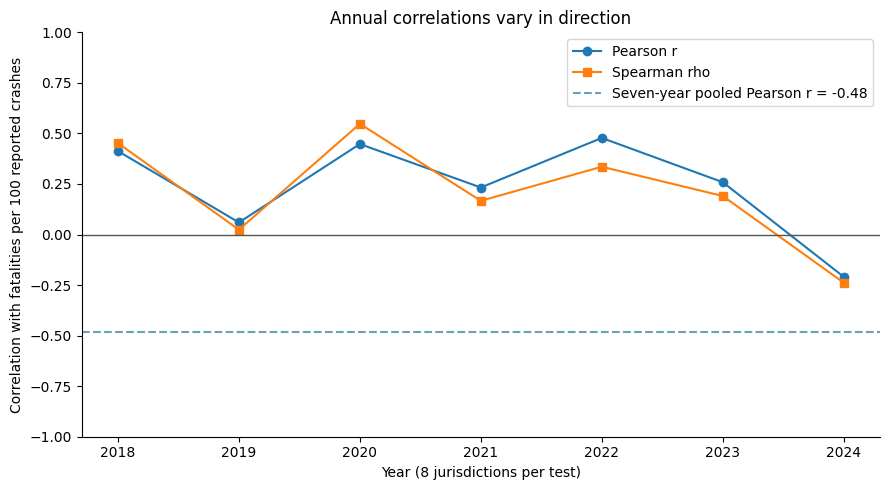

In [8]:
annual_correlation_rows = []
for year, group in safety.groupby("Year"):
    annual_fatality_rate = group["Cyclist_Fatalities"] / group["Total_Crashes"] * 100
    annual_mileage = group["Protected_Lane_Miles"]
    if len(group) < 3:
        raise ValueError(f"Too few jurisdictions to test year {year}.")
    pearson_annual = pearsonr(annual_mileage, annual_fatality_rate)
    spearman_annual = spearmanr(annual_mileage, annual_fatality_rate)
    annual_correlation_rows.append({
        "Year": int(year),
        "Jurisdictions": group["State"].nunique(),
        "Pearson r": pearson_annual.statistic,
        "Pearson p-value": pearson_annual.pvalue,
        "Spearman rho": spearman_annual.statistic,
        "Spearman p-value": spearman_annual.pvalue,
    })

annual_correlations = pd.DataFrame(annual_correlation_rows).set_index("Year").sort_index()
display(annual_correlations.style.format({
    "Pearson r": "{:.3f}",
    "Pearson p-value": "{:.3f}",
    "Spearman rho": "{:.3f}",
    "Spearman p-value": "{:.3f}",
}))
print(f"Seven-year pooled reference: Pearson r = {pearson_result.statistic:.3f} (p={pearson_result.pvalue:.3f}); "
      f"Spearman rho = {spearman_result.statistic:.3f} (p={spearman_result.pvalue:.3f}).")
print("Every annual test uses eight jurisdictions; p-values are not below 0.05 in any year.")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(annual_correlations.index, annual_correlations["Pearson r"], marker="o", label="Pearson r")
ax.plot(annual_correlations.index, annual_correlations["Spearman rho"], marker="s", label="Spearman rho")
ax.axhline(0, color="#555555", linewidth=1)
ax.axhline(pearson_result.statistic, color="#2878A5", linestyle="--", alpha=0.7,
           label=f"Seven-year pooled Pearson r = {pearson_result.statistic:.2f}")
ax.set_xticks(annual_correlations.index)
ax.set_ylim(-1, 1)
ax.set_xlabel("Year (8 jurisdictions per test)")
ax.set_ylabel("Correlation with fatalities per 100 reported crashes")
ax.set_title("Annual correlations vary in direction")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## High crash and fatality totals: outlier screen

Use the 1.5×IQR upper fence to screen (1) each jurisdiction's total across 2018–2024 and (2) individual state-year observations. Raw counts are not adjusted for population or cycling exposure, so a high total is not the same as a high per-person risk. With only eight jurisdictions, treat the state-total IQR flag as a descriptive screen.

,Total_Crashes,Cyclist_Fatalities,Total_Crashes_upper_IQR_outlier,Cyclist_Fatalities_upper_IQR_outlier
State,,,,
PA,"23,926",562,False,True
DC,"21,496",405,False,False
CT,"21,012",425,False,False
MA,"20,785",357,False,False
NY,"18,252",271,False,False
VA,"18,227",318,False,False
NJ,"16,962",358,False,False
MD,"16,723",311,False,False


,Q1,Q3,Upper IQR fence,State-year outlier count,"Top observations (year, state, value)"
Measure,,,,,
Total_Crashes,"1,870.75","3,815.50","6,732.62",0,"2020, MA, 4941; 2018, PA, 4856; 2024, VA, 4824"
Cyclist_Fatalities,29.75,72.00,135.38,0,"2022, PA, 133; 2018, PA, 129; 2024, CT, 110"


State-total outliers:
Total_Crashes: none; upper fence = 25,966.38
Cyclist_Fatalities: ['PA']; upper fence = 550.62
State-year flags are screened separately in the table; totals are raw counts, not exposure-adjusted rates.


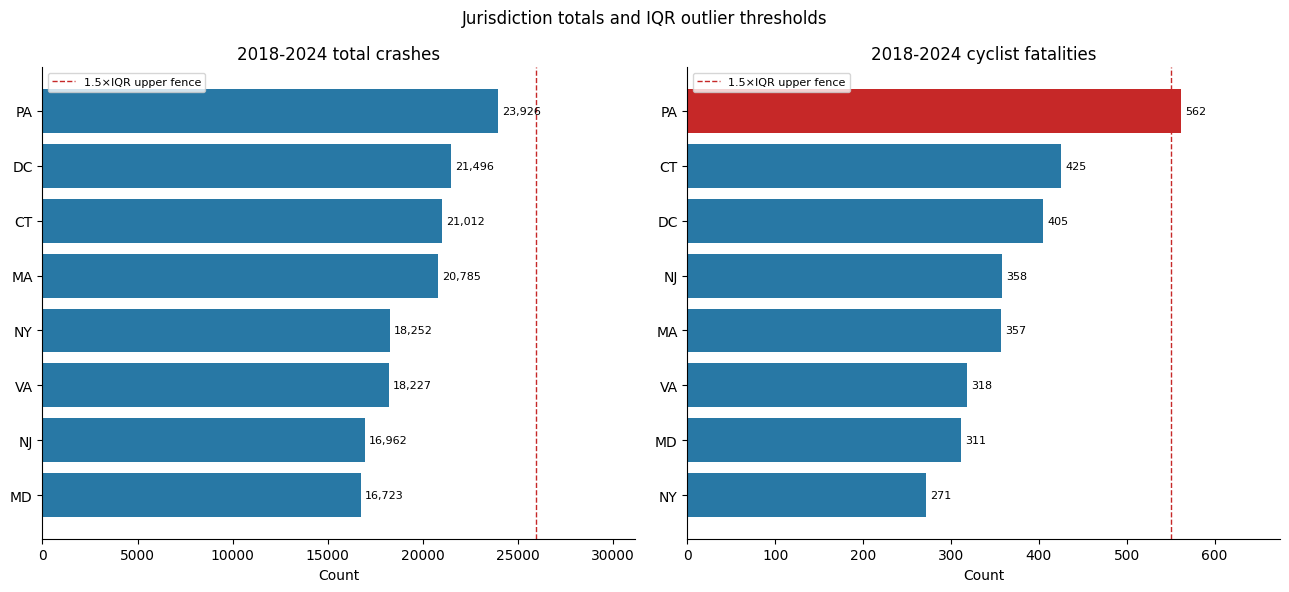

In [9]:
state_totals = safety.groupby("State").agg(
    Total_Crashes=("Total_Crashes", "sum"),
    Cyclist_Fatalities=("Cyclist_Fatalities", "sum"),
)
state_iqr_fences = {}
for field in ["Total_Crashes", "Cyclist_Fatalities"]:
    q1 = state_totals[field].quantile(0.25)
    q3 = state_totals[field].quantile(0.75)
    upper_fence = q3 + 1.5 * (q3 - q1)
    state_iqr_fences[field] = upper_fence
    state_totals[f"{field}_upper_IQR_outlier"] = state_totals[field] > upper_fence

display(state_totals.sort_values("Total_Crashes", ascending=False).style.format({
    "Total_Crashes": "{:,.0f}",
    "Cyclist_Fatalities": "{:,.0f}",
    "Total_Crashes_upper_IQR_outlier": "{}",
    "Cyclist_Fatalities_upper_IQR_outlier": "{}",
}))

annual_outlier_rows = []
for field in ["Total_Crashes", "Cyclist_Fatalities"]:
    q1 = safety[field].quantile(0.25)
    q3 = safety[field].quantile(0.75)
    upper_fence = q3 + 1.5 * (q3 - q1)
    flagged = safety.loc[safety[field] > upper_fence, ["Year", "State", field]]
    highest = safety.nlargest(3, field)[["Year", "State", field]]
    annual_outlier_rows.append({
        "Measure": field,
        "Q1": q1,
        "Q3": q3,
        "Upper IQR fence": upper_fence,
        "State-year outlier count": len(flagged),
        "Top observations (year, state, value)": "; ".join(
            f"{int(row.Year)}, {row.State}, {int(getattr(row, field))}"
            for row in highest.itertuples(index=False)
        ),
    })
annual_outlier_summary = pd.DataFrame(annual_outlier_rows).set_index("Measure")
display(annual_outlier_summary.style.format({
    "Q1": "{:,.2f}",
    "Q3": "{:,.2f}",
    "Upper IQR fence": "{:,.2f}",
}))

print("State-total outliers:")
for field in ["Total_Crashes", "Cyclist_Fatalities"]:
    flags = state_totals.index[state_totals[f"{field}_upper_IQR_outlier"]].tolist()
    print(f"{field}: {flags if flags else 'none'}; upper fence = {state_iqr_fences[field]:,.2f}")
print("State-year flags are screened separately in the table; totals are raw counts, not exposure-adjusted rates.")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, field, title in zip(
    axes,
    ["Total_Crashes", "Cyclist_Fatalities"],
    ["2018-2024 total crashes", "2018-2024 cyclist fatalities"],
):
    values = state_totals[field].sort_values()
    colors = ["#C62828" if state_totals.loc[state, f"{field}_upper_IQR_outlier"] else "#2878A5"
              for state in values.index]
    bars = ax.barh(values.index, values.values, color=colors)
    ax.bar_label(bars, labels=[f"{value:,.0f}" for value in values.values], padding=3, fontsize=8)
    ax.axvline(state_iqr_fences[field], color="#C62828", linestyle="--", linewidth=1,
               label="1.5×IQR upper fence")
    ax.set_xlim(0, max(values.max(), state_iqr_fences[field]) * 1.2)
    ax.set_title(title)
    ax.set_xlabel("Count")
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Jurisdiction totals and IQR outlier thresholds")
fig.tight_layout()
plt.show()

## Limitations

- **No local city crash data:** This workbook reports jurisdiction-level figures, so it cannot identify crash patterns for the local city, neighborhoods, or proposed routes.
- **No cycling exposure measure:** Bicycle trips or miles traveled are not available. Counts and fatalities per reported crash are not measures of risk per trip or mile traveled.
- **Geographic units are not equivalent:** State-level safety figures are not directly comparable to neighborhood-level population, access, or survey data. They describe different places and populations, so they should not be combined as if they were measured at the same scale.
- **Correlation is not causation:** The mileage-safety associations are observational and unadjusted; they do not establish that protected-lane mileage caused changes in crashes, injuries, or fatalities.